<a href="https://colab.research.google.com/github/damourmaniragaba/Prediction-Markets-Analysis/blob/main/FINAL_Phase_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# __Final Project Phase 3__
### What makes a successful trader on Polymarket?
Ha An Pham Le (hp482), Alanna (ay444), Jean D'Amour Maniragaba (jm2876)

In [ ]:
# imports and settings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm
%matplotlib inline
plt.rcParams['figure.figsize'] = (10.0, 6.0)

# load the clean files made by our data cleaning notebook (ids are read as text, not numbers)
positions_clean_df = pd.read_csv('positions_clean.csv', dtype={'event_id': str, 'token_id': str})
traders_clean_df = pd.read_csv('traders_clean.csv')
print('positions:', positions_clean_df.shape)
print('traders:', traders_clean_df.shape)

positions: (579160, 19)
traders: (1844, 15)


# __INTRODUCTION__

### Background information

Polymarket is the largest prediction market: a website where people buy and sell shares on whether future events will happen, from who will win an election to whether Bitcoin will pass a certain price by Friday. A share pays 1 dollar if its outcome happens and nothing if it doesn't, so its price works like the crowd's estimate of the probability (Wolfers & Zitzewitz, 2004). Polymarket presents these prices as forecasts of real-world events (Britannica, n.d.).

But a prediction market is also a zero-sum game: every dollar one trader wins, another trader loses. So for the people using Polymarket, the real question is who ends up on the winning side. Research on stock trading suggests that very few people do: among individual investors, the households that trade the most earn the lowest returns (Barber & Odean, 2000), and among day traders, less than 1% earn reliable profits after fees (Barber et al., 2014). Polymarket also ranks its most profitable traders on a public leaderboard, and people tend to imitate successful traders. In an experiment, showing people how much others earned made them take more risk, and letting them copy others directly increased risk even more (Apesteguia et al., 2020). If the traders at the top are lucky risk-takers rather than skilled ones, ordinary users who copy them could lose money. A leaderboard also only shows the winners, and in finance, studies that only include the funds that survived overstate how well funds perform (Brown et al., 1992).

### What we study and why

Not every trade or trader on Polymarket does equally well, though: prediction market traders follow very different strategies, from low-risk arbitrage to large bets on one side (Rothschild & Sethi, 2016). Therefore, we are interested in exploring which characteristics of a trade, and which behaviors of a trader, are related to making money. Specifically, research on betting markets finds that bets on unlikely outcomes ("longshots") lose the most money per dollar (Snowberg & Wolfers, 2010), so we look at the price a trader pays for a share, which tells us how likely the market thinks the outcome is. Sports makes up about half of the positions in our data, and sports bettors are known for predictable biases such as backing their favorite teams (Levitt, 2004), so we also look at how much of their money traders put on sports. Because heavy trading goes with lower returns in the stock market (Barber & Odean, 2000), we include how often a wallet trades, and we include how long it has been on Polymarket as a measure of experience. Finally, so that we don't look only at the winners, we compare the 1,000 most profitable wallets on the leaderboard with 1,000 randomly chosen ordinary wallets.

**Main question:** Which characteristics of a position, and which behaviors of a trader, are associated with higher returns on Polymarket, the largest prediction market?

**Sub-questions**
1. **Position level:** Is a position's return related to its **entry price**, **category** (sports, politics, crypto, weather, tech, culture, econ), **size**, **holding time**, and the **event's trading volume**?
2. **Trader level:** Is a trader's return related to how much of their money they put on **sports**, how much **risk** they take, how **often** they trade, and how **long** they have been on Polymarket, after accounting for whether they are a **leaderboard (top) trader** or an **ordinary trader**?

**How we measure success: return on investment (ROI)**
- ROI = profit or loss ÷ money spent.
- **Position ROI** is the return on one bet: that position's profit ÷ the money spent on it. A contract bought at price *p* returns $(1-p)/p$ if it wins and $-1$ if it loses.
- **Trader ROI** is the return on everything one trader did: the total profit across all their positions ÷ the total money they spent. Bigger bets count more, so it is not the average of their position ROIs.
- We use ROI instead of dollar profit because dollar profit mostly tells us how much money a trader has, not how good their trades are.

**Summary of findings:** Neither of our hypotheses was supported. Cheap (highRisk) positions did not have a lower ROI than mediumRisk positions: their average ROI was about 2.5 higher, driven by a few enormous wins, even though most of them lost everything. The share of money a trader puts on sports was not clearly related to their ROI. Instead, leaderboard traders and traders who put more of their money on cheap shares had higher returns.

# __DEFINITIONS__
- Prediction market - A website where people buy and sell shares on whether future events will happen
- Event / market - a topic (e.g., "who will win the 2026 NBA Finals?"); can contain several markets, each a single yes/no question
- Share / contract - pays \$1 if its outcome happens and \$0 if not, so its price (\$0 to \$1) works like the market's estimated probability
- Position - all of one wallet's shares in one outcome of one market, from the first purchase until it is sold or the market ends
- Resolve / redeem - a market resolves when the outcome is decided; traders then cash in winning shares for \$1 each
- Wallet - a trading account, identified by an address on the blockchain; we occasionally refer to a wallet as a "trader" for convenience, but it's possible for one trader to have multiple wallets
- Leaderboard - Polymarket's public ranking of wallets by profit
- PnL (Profit and Loss) - how much money a position or trader made or lost
- ROI (Return on Investment) - profit or loss ÷ money spent
- Cost basis - money spent on a position (shares bought * average price)
- Volume - Total dollar amount traded on an event by everyone
- HHI | Herfindahl-Hirschman Index: a 0-to-1 measure of how concentrated something is (here, a trader's money across categories)

**Example:** you buy one "Yes" share for \$0.10. If the event happens, it pays \$1, so you make \$0.90 (ROI = 0.90 ÷ 0.10 = +900%). If it doesn't, you get \$0 (ROI = −100%). Cheap shares usually lose everything and occasionally pay a lot.

# __DATA DESCRIPTION AND CLEANING__
### Data collection

**Source.** All data comes from Polymarket's two free, public APIs (no key needed):
- the **Data API** (https://data-api.polymarket.com/v2) for the leaderboard, trades, positions, and user stats;
- the **Gamma API** (https://gamma-api.polymarket.com) for each event's tags and trading volume.

Polymarket records every trade on the Polygon blockchain, so the data can be checked against public records.

**How we built the sample**
1. **Top traders:** the 1,000 wallets with the highest all-time profit on the leaderboard.
2. **Random traders:** we listed 2,000 events that closed between Oct 1, 2025 and Oct 1, 2026 and randomly picked 1,500 of them. For each, we took one random trader from the most recent trades in the event's first market, excluding top traders. We kept the first 1,000 different wallets.
3. **Positions:** for each of the 2,000 wallets, we downloaded up to 500 of its most recent positions for each of three statuses:
   - `CLOSED`: sold or cashed in;
   - `REDEEMABLE`: the market resolved and the trader still holds the shares;
   - `REDEEMABLE_LOST`: the market resolved and the trader lost.
   
   We only kept positions with activity between Oct 1, 2025 and Oct 1, 2026. We need all three statuses because a losing bet held to the end is worth \$0, so traders often never cash it in. If we only downloaded `CLOSED` positions, many losses would be missing.
4. **Join dates** for each wallet, from `/user-stats`.
5. **Event information** (tags and volume) for every event in our positions, from the Gamma API.

Running the collection code takes over 1 hour. It saved five raw files (745,709 raw positions and 132,321 events). After cleaning, 1,844 of the 2,000 wallets still have at least one position, so our trader table has 1,844 rows. Our collection and cleaning code is in a separate notebook (linked below).

Data collected on 10/11/2026.

### Data cleaning
All of our collection and cleaning code is in a separate notebook: https://colab.research.google.com/drive/1ebqInnQ4C9gF8P11VGwltkmy8kyVQKcE?usp=sharing. It reads the raw files and saves the two clean files this notebook loads. It:
1. Keeps only the columns we use and drops profile information like display names.
2. Removes duplicate positions (the same resolved position can appear under two statuses): 745,709 → 612,956 rows.
3. Removes positions with a price outside \$0–\$1: 612,956 → 610,701 rows.
4. Computes ROI and removes impossible values (below −1 or above $(1-p)/p$): 610,701 → 579,160 rows.
5. Computes holding time, price group, and category for each position, and adds each event's trading volume (a volume of \$0 is treated as missing).
6. Replaces wallet addresses with trader numbers to protect traders' privacy.
7. Summarizes positions into one row per trader (trader ROI, highRiskShare, sportsShare, CategoryHHI, tenure, positions per month).

- Raw files: https://drive.google.com/drive/folders/1qBlrM1k48SQcTbSTcElOIv_jracyIzQe
- Clean files (`positions_clean.csv`, `traders_clean.csv`): https://drive.google.com/drive/folders/1wDT1XpYTAMKCWmaXdpMVM4nS-b_bMojz?usp=sharing
- Original source: Polymarket Data API documentation, https://docs.polymarket.com/api-reference/data-api/overview

### __MOTIVATION__
__Why was this dataset created?__

- Polymarket provides this public API so developers and users can read wallet-level portfolios, trade feeds, market states, and leaderboards. Polymarket's view is that when many people risk their own money on their opinions, market prices become accurate forecasts, because traders have a reason to be informed and honest (Wolfers & Zitzewitz, 2004). Publishing the data openly lets anyone check those forecasts against what actually happened, which Polymarket presents as a way to fight misinformation. It also turns market probabilities into a free public tool for researchers, traders, and market makers.
- Polymarket also benefits as a business. Open, checkable data makes the platform more credible to new users who are deciding whether to trust it with their money. It also lets outside developers build tools on top of Polymarket, such as dashboards and trading bots, which bring more users and trading volume to the platform.

__How did you create this dataset? What tools, procedures, and data sources did you use?__

- Our group created this dataset using Polymarket's public APIs based on their international markets.
- We credit Polymarket for making its trading data free and openly available, the Polygon blockchain for recording every trade publicly, and UMA, the system Polymarket uses to decide how markets resolve.
- We acquired this dataset with Python's `requests` library calling Polymarket's Data API and Gamma API (see Data collection). Every value was recorded by Polymarket when the trade happened. We only calculated new columns (ROI, holding time, categories, HHI). The data includes positions with activity from Oct 1, 2025 to Oct 1, 2026.

### __COMPOSITION__
__What are the observations (rows) and the attributes (columns)?__

`positions_clean.csv`: one row per position, i.e., one trader's holdings in one outcome (e.g., "Yes") of one market, with activity between Oct 1, 2025 and Oct 1, 2026.
- `trader_id`: the number we assigned to each trader in place of their wallet address
- `sample_group`: which sample the trader came from (leaderboard or random)
- `query_status`: the position's status
  * CLOSED: sold or cashed in
  * REDEEMABLE: market resolved, shares still held
  * REDEEMABLE_LOST: market resolved and trader lost
- `token_id`: ID of the outcome the trader bought
- `condition_id`: ID of the market the outcome belongs to
- `event_id`: ID of the event the market belongs to (one event can have multiple markets)
- `title`: the market's question
- `avg_price`: average price paid per share (\$0–\$1)
- `total_size`: number of shares purchased
- `cost_basis`: money spent on the position in dollars (`total_size` * `avg_price`)
- `total_pnl`: profit or loss on this position, in dollars (PnL = profit and loss)
- `roi`: return on investment (`total_pnl` / `cost_basis`)
- `won`: whether an investment made money
- `first_entry_at`: first purchase time (originally in epoch seconds, converted to datetime in clean file)
- `last_event_at`: last activity time (originally in epoch seconds, converted to datetime in clean file)
- `holding_days`: days held
- `price_group`: highRisk (under \$0.20), mediumRisk, or lowRisk (\$0.80 or more)
- `category`: the event's category (crypto, sports, weather, econ, tech, culture, politics)
  * "other" if none of the tags match
  * "unknown" if we have no event information
- `event_volume`: the event's total trading volume across all traders, in dollars

`traders_clean.csv`: one row per trader, built by summarizing trader's rows in `positions_clean.csv`
- `trader_id`
- `sample_group`
- `n_positions`: number of positions the trader has in our data
- `total_spent`: total money spent across all positions, in dollars (sum of `cost_basis`)
- `total_pnl`: total profit or loss across all of the trader's positions, in dollars
- `trader_roi`: overall return on investment (`total_pnl` ÷ `total_spent`)
- `win_rate`: share of the trader's positions that made money
- `highRisk_share`: share of the trader's money spent on contracts priced under \$0.20; our measure of risk-taking
- `sports_share`: share of the trader's money spent on sports positions (the main input for Hypothesis 2)
- `median_holding_days`: median number of days the trader held a position
- `category_hhi`: how focused the trader is on few categories (0 to 1; 1 means all money in one category). It is the sum of the squared shares of money spent in each category, leaving out "unknown"
- `tenure_months`: months from the trader's Polymarket join date to Oct 1, 2026
- `join_date_readable`: the date the trader joined Polymarket
- `positions_per_month`: the average number of positions per month in our one-year window (`n_positions` / 12)
- `top_trader`: 1 if the trader is from the leaderboard, 0 if from the random sample

### __COLLECTION PROCESS__
__What processes might have influenced what data was observed and recorded and what was not?__

- Polymarket decides which markets exist and how they're tagged, so the categories we used reflect its choices.
- The leaderboard ranks wallets by all-time profit, so our top group was chosen *because* it made money, which is close to the outcome we study. Leaderboard traders having a higher ROI is therefore built into our sample, not a finding, so we only use `top_trader` as a control.
- Random traders were picked from recent trades in random markets, so wallets that trade a lot are more likely to be picked.
- We downloaded at most 500 positions per status per wallet, so for very active wallets we only see their most recent positions.

__What preprocessing was done, and how did the data come to be in the form we are using?__

We started by removing duplicates, invalid prices, missing profits, and impossible ROI values. Then, we calculated ROI, holding time, price groups, and categories. After that, we replaced wallet addresses with trader numbers and dropped names, because rows describe real people's gains and losses. Finally, we summarized positions into one row per trader. Each step is explained in our data cleaning notebook (linked above).

### __PEOPLE AND USES__
__If people are involved, were they aware of the data collection, and what purpose did they expect the data to be used for?__

Upon joining Polymarket, traders agree to terms and conditions stating that their usernames, profits, losses, and trades are public on the blockchain. However, since they were not told about our project, we removed information like usernames to help preserve their privacy. Either way, only Polymarket activity is visible, so we don't know anything about traders' personal identities.

### __IS THE DATA RELIABLE?__
- **Trades can be checked.** Every trade is recorded on the public Polygon blockchain, so anyone can check that the trades happened.
- **Profit is calculated by Polymarket.** `total_pnl` comes from Polymarket's API, not straight from the blockchain, and we can't see exactly how it is calculated. We did check that every ROI is possible for its price (cleaning Step 5) and removed the 31,541 positions (5.2%) where it wasn't.
- **Some information is missing.** Event volume is missing for 4.6% of positions (14.4% of crypto positions), and Polymarket did not return a join date for 92 of our 1,844 traders. We discuss how this could affect our results in our Limitations.
- **The data is a snapshot.** We downloaded it on 10/11/2026. Polymarket's data keeps changing, so rerunning our collection code later would give slightly different numbers. This is why we saved the raw files.

### __EXPLORATORY ANALYSIS__
We show only the parts of our Phase 2 exploratory analysis that led to our hypotheses. The summary at the end of this section explains how.

### Summary statistics
We chose to show the 1st and 99th percentiles in addition to 25th, 50th, and 75th because money on Polymarket is very unevenly spread.

In [ ]:
# Summary statistics for the position-level variables
positions_clean_df[['avg_price', 'cost_basis', 'roi', 'holding_days', 'event_volume']].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).round(2)

,avg_price,cost_basis,roi,holding_days,event_volume
count,579160.00,579160.00,579160.00,579160.00,5.524510e+05
mean,0.52,10173.38,0.59,20.51,4.088706e+07
std,0.33,249083.10,11.96,51.18,3.186550e+08
min,0.00,0.00,-1.01,0.00,1.920000e+00
1%,0.00,0.05,-1.00,0.00,6.563200e+02
25%,0.25,10.00,-1.00,0.12,9.346304e+04
50%,0.51,99.99,0.00,0.61,6.105582e+05
75%,0.83,1266.00,0.28,8.70,3.826457e+06
99%,1.00,139928.23,12.14,259.64,7.040968e+08
max,1.00,60966887.64,999.00,1491.76,4.327989e+09


Observations: Cost basis, ROI, holding days, and event volume are all very right-skewed. The median position costs about \$100, while the mean is over \$10,000 and the largest single position cost about \$61 million. The median ROI is 0 (the trader got their money back), but the mean is 0.59, because a few positions win disproportionately more (the maximum ROI is 999). The median position is held for about 15 hours, but the mean is 20.5 days. The median event has about \$611k of trading volume, while the mean is about \$41 million. Average price is the exception: its mean (0.52) and median (0.51) are close, because prices can only be between \$0 and \$1. Because cost basis, holding time, and event volume are this skewed, we use their natural logs in the position model.

### Our outcome: ROI
ROI is what we are trying to explain, so we need to know its shape. We expect many positions at −1 (total losses) and a long tail of big wins. For this plot only, values above the 99th percentile are shown at the 99th percentile so the rest is visible.

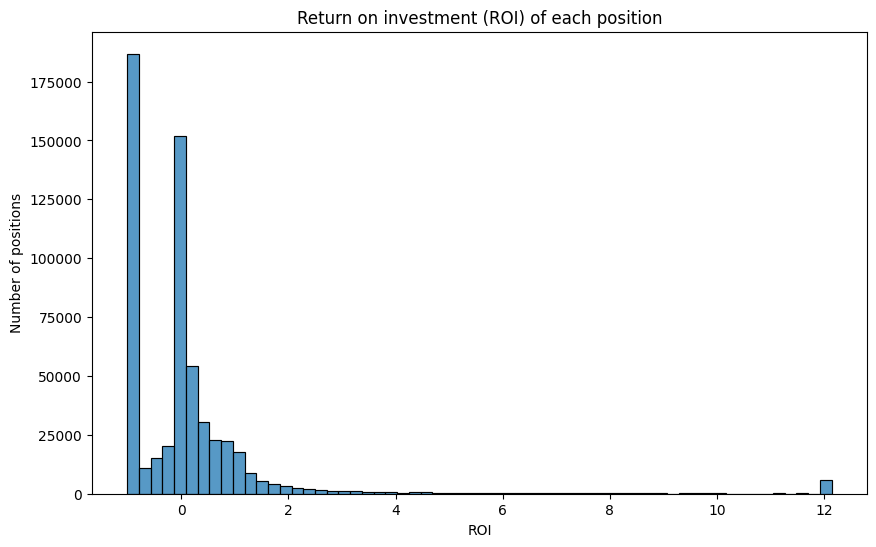

In [ ]:
# Distribution of position ROI (top 1% capped for the plot)
roi_99 = positions_clean_df['roi'].quantile(0.99)
sns.histplot(x=positions_clean_df['roi'].clip(upper=roi_99), bins=60)
plt.title('Return on investment (ROI) of each position')
plt.xlabel('ROI')
plt.ylabel('Number of positions')
plt.show()

Observations: Most positions seem to have a ROI near -1, meaning they lost everything, or near 0. The number of positions drops steeply as ROI increases.

There's a small bump at the right edge, as we grouped the top 1% of positions into the last bar. We suspect that the extreme returns come from wins from very cheap shares.

This is why we do not cap ROI in Hypothesis 1: these rare big wins on cheap shares are exactly what decides whether cheap shares pay off on average.

### Entry prices
Entry price is the basis of our risk measure. We check where each group buys, and whether there are enough positions in each price group to run our analysis.

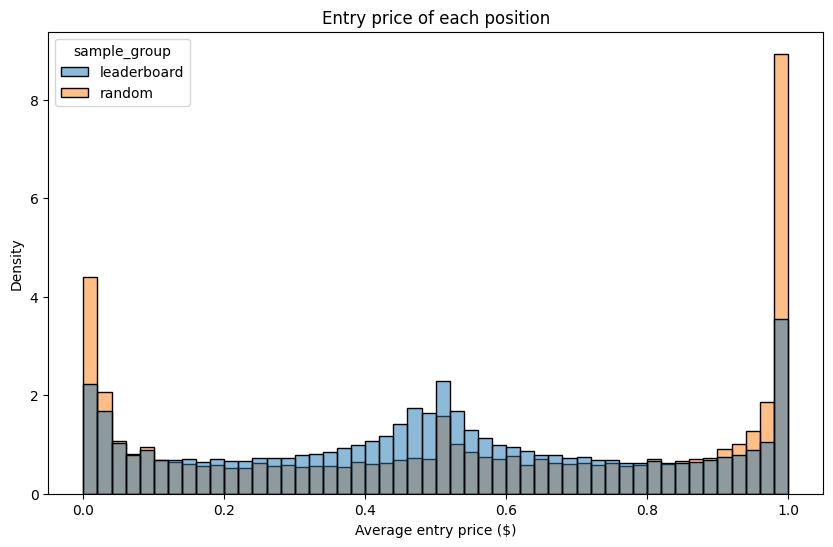

In [ ]:
# Distribution of entry prices by group
sns.histplot(data=positions_clean_df, x='avg_price', hue='sample_group', bins=50,
             stat='density', common_norm=False)
plt.title('Entry price of each position')
plt.xlabel('Average entry price ($)')
plt.show()

Observations: Both groups often buy shares priced at \$0.98 or more, which the market treats as at least 98% likely to happen, but this is far more common for wallets from the random group. Both groups also buy many high-risk shares priced under \$0.02, but once again the density is more than twice as high for the random group as for the leaderboard group. There's also a small bump for both groups around \$0.50, in the medium-risk range, where the density for leaderboard wallets is slightly higher. Overall, wallets from the random group buy at the extremes more than leaderboard wallets do: 59.2% of random positions are highRisk or lowRisk, compared with 40.3% of leaderboard positions.

### Categories
Sports has by far the most positions (about half of our data). Below is the average ROI in each category. ROI is capped at the 1st and 99th percentiles so that one huge win cannot dominate a bar. The thin black line on top of each bar is its 95% confidence interval.

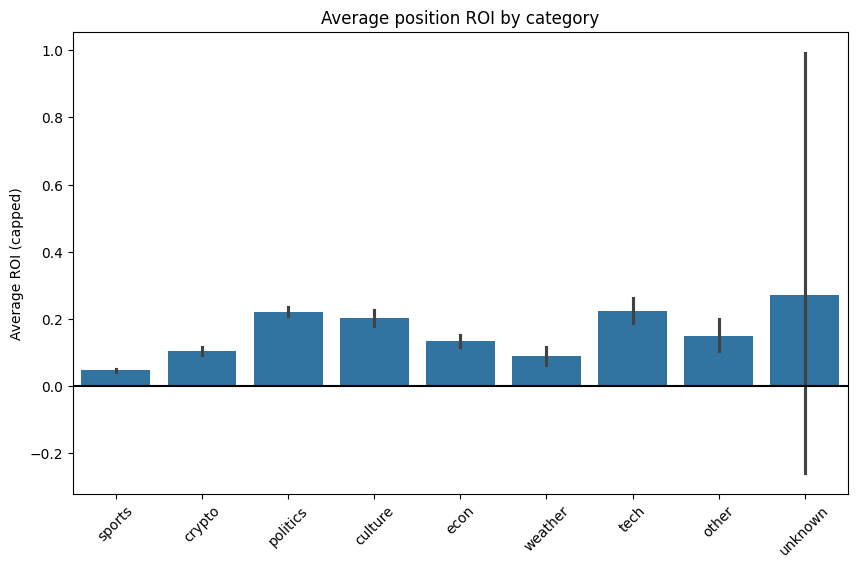

In [ ]:
# Average ROI by category (ROI capped at the 1st and 99th percentiles, for this plot only)
roi_1 = positions_clean_df['roi'].quantile(0.01)
roi_99 = positions_clean_df['roi'].quantile(0.99)
positions_clean_df['roi_capped'] = positions_clean_df['roi'].clip(roi_1, roi_99)
category_order = positions_clean_df['category'].value_counts().index
sns.barplot(data=positions_clean_df, x='category', y='roi_capped', order=category_order)
plt.axhline(0, color='black')
plt.title('Average position ROI by category')
plt.xlabel('')
plt.ylabel('Average ROI (capped)')
plt.xticks(rotation=45)
plt.show()

Observations: Despite being the category with the most positions, sports has the lowest ROI, followed by crypto. On the other hand, technology, politics, and culture have the highest average ROI, but their confidence intervals overlap, so we cannot say for certain which of the three is the highest. The confidence interval for technology is wider because it has fewer positions. We suspect that every category's average is positive because a small number of large wins on cheap contracts pull the averages up.

"Unknown" shows a large average ROI with a very wide confidence interval because it contains very few positions (under 0.1% of our data), so we draw no conclusions from it.

This is the starting point for Hypothesis 2.

### __What our EDA told us__
- **Returns are extreme.** Most positions lose everything or break even, and a few cheap positions win very big. This made us ask whether cheap positions pay off on average (Hypothesis 1), and it is why we don't cap ROI in that test.
- **Ordinary traders buy at the extremes.** Random wallets put more of their positions at very low and very high prices than leaderboard wallets, which suggested that entry price is linked to who makes money (Hypothesis 1).
- **Sports is the most traded category but has the lowest average ROI.** This led to Hypothesis 2: traders who put more of their money on sports may earn less overall.
- **Money spent, holding time, and event volume are very skewed**, so we use their natural logs in our models.
- **Missing values are not random.** Event volume is missing mostly for crypto positions, and tenure mostly for random traders, so the rows we leave out are not a random sample. We discuss this in our Limitations.

# __PREREGISTRATION STATEMENTS__
Our hypotheses and models are the same as in our Phase 2 preregistration. For Phase 3, we added why we expect each result, and how we test significance.

### Preregistration Statement 1
**Hypothesis 1:** High-risk positions (positions bought under 20 cents) have a lower ROI than medium-risk positions (positions bought between 20 and 80 cents).

**Why we expect this.** Studies of betting markets have found the "favorite–longshot bias" for decades: bets on unlikely outcomes lose more money per dollar than bets on likely outcomes (Thaler & Ziemba, 1988). One explanation is that people overestimate small probabilities, so they pay too much for longshots (Snowberg & Wolfers, 2010). Page and Clemen (2013) found the same pattern in prediction markets: cheap contracts won less often than their prices implied. On Polymarket, a cheap share is a longshot, so if the bias exists here, highRisk positions should have a lower ROI.

**Why 20 cents and 80 cents.** These studies don't use one fixed cutoff for a longshot, so we chose cutoffs that are the same distance from 0 and 1 dollar. To look at prices without depending on this choice, we also plot win rate against price in ten price ranges, which uses no cutoffs at all.

**Analysis:** For data where each row represents a position, we run a linear regression where we input the price groups (as dummy variables) and output the position's ROI (profit ÷ money spent). We also input money spent, holding time, and event volume (each as a natural log) and event categories (as dummy variables, with sports as the reference) as controls. The mediumRisk dummy will be our reference variable, so we will test whether $\beta_{highRisk} < 0$. Holding times under one hour are set to one hour before taking the log, and positions with an unknown category or missing event volume are left out.

**Significance:** We use a t-test on $\beta_{highRisk}$ from the statsmodels regression table. The null hypothesis is $\beta_{highRisk} = 0$ (no difference between highRisk and mediumRisk positions), and the alternative is $\beta_{highRisk} < 0$, so the test is one-tailed. We reject the null hypothesis if the one-tailed p-value is below 0.05.

$$ROI = \alpha + \beta_{highRisk}\,highRisk + \beta_{lowRisk}\,lowRisk + \beta_3 \log(CostBasis) + \beta_4 \log(HoldingDays) + \beta_5 \log(EventVolume) + \text{category dummies} + \varepsilon$$

### Preregistration Statement 2
**Hypothesis 2:** Traders who spend a larger share of their money on sports have a lower ROI than traders who spend it in other categories.

**Why we expect this.** Sports betting markets are known for predictable biases: many bettors back their favorite teams and popular sides, and bookmakers set prices to profit from this (Levitt, 2004). Sports markets on Polymarket also open and close within hours, so ordinary traders compete with fast, often automated traders who react to new information first. Our EDA also showed that sports has the lowest average position ROI of any category.

**Analysis:** We run a linear regression where we input sportsShare (the share of a trader's money spent on sports positions) and output trader ROI. We also input top trader (as a dummy variable, indicating whether this trader comes from the leaderboard or not, with random traders as the reference), highRiskShare, total money spent (as a natural log), positions per month, and tenure in months as controls. We will test whether $\beta_{sportsShare} < 0$. Traders with no tenure (no join date) are left out.

**Significance:** We use a t-test on $\beta_{sportsShare}$ from the statsmodels regression table. The null hypothesis is $\beta_{sportsShare} = 0$ (sportsShare is unrelated to trader ROI), and the alternative is $\beta_{sportsShare} < 0$, so the test is one-tailed. We reject the null hypothesis if the one-tailed p-value is below 0.05.

$$traderROI = \alpha + \beta_{sportsShare}\,sportsShare + \beta_2\,topTrader + \beta_3\,highRiskShare + \beta_4 \log(totalSpent) + \beta_5\,positionsPerMonth + \beta_6\,tenure + \varepsilon$$

# __DATA ANALYSIS__
## Hypothesis 1: entry price and position ROI
We turn price group and category into 0/1 dummy variables, take the natural log of the three skewed controls, and leave out positions with an unknown category or missing event volume.

In [ ]:
# Hypothesis 1 data: one row per position, leaving out the 40 positions with an unknown category
pos_df = positions_clean_df[positions_clean_df['category'] != 'unknown'].copy()

# price group dummies (mediumRisk is the reference)
pos_df['highRisk'] = (pos_df['price_group'] == 'highRisk').astype(int)
pos_df['lowRisk'] = (pos_df['price_group'] == 'lowRisk').astype(int)

# category dummies (sports is the reference)
category_dummies = ['politics', 'crypto', 'weather', 'tech', 'culture', 'econ', 'other']
for category in category_dummies:
    pos_df[category] = (pos_df['category'] == category).astype(int)

# natural logs of the skewed controls (holding times under one hour are set to one hour first)
pos_df['log_cost_basis'] = np.log(pos_df['cost_basis'])
pos_df['log_holding_days'] = np.log(pos_df['holding_days'].clip(lower=1/24))
pos_df['log_event_volume'] = np.log(pos_df['event_volume'])

# the main model also needs event volume, so leave out positions where it is missing
h1_df = pos_df.dropna(subset=['log_event_volume']).copy()
h1_inputs = ['highRisk', 'lowRisk', 'log_cost_basis', 'log_holding_days', 'log_event_volume'] + category_dummies
print('positions in the model:', len(h1_df), 'of', len(positions_clean_df))

positions in the model: 552451 of 579160


In [ ]:
# Hypothesis 1 regression
h1_model = LinearRegression()
h1_model.fit(h1_df[h1_inputs], h1_df['roi'])

print('intercept:', round(h1_model.intercept_, 3))
print('R squared:', round(h1_model.score(h1_df[h1_inputs], h1_df['roi']), 4))
pd.DataFrame({'input': h1_inputs, 'coefficient': h1_model.coef_}).round(3)

intercept: -1.4
R squared: 0.0112


,input,coefficient
0,highRisk,2.504
1,lowRisk,-0.041
2,log_cost_basis,-0.111
3,log_holding_days,-0.026
4,log_event_volume,0.141
5,politics,0.027
6,crypto,0.733
7,weather,-0.074
8,tech,-0.374
9,culture,-0.043


**Summarizing.** Holding the other inputs fixed, a highRisk position's ROI is on average 2.50 higher than a mediumRisk position's (ROI is a fraction, so 2.50 means 250 percentage points higher). This is the opposite of what Hypothesis 1 predicted. A lowRisk position's ROI is 0.04 lower than a mediumRisk position's (4 percentage points).

For the logged controls, doubling an input changes ROI by about 0.69 × its coefficient (because log(2) ≈ 0.69):
- doubling the money spent corresponds to an ROI about 0.08 lower;
- doubling the holding time corresponds to an ROI about 0.02 lower;
- doubling the event's trading volume corresponds to an ROI about 0.10 higher.

Among categories, crypto positions have the highest ROI, 0.73 higher than sports positions, and tech positions the lowest, 0.37 lower than sports.

The R² is 0.011, so these inputs explain only about 1% of the variation in ROI. That's expected: whether a single bet wins is mostly luck, so no model can explain much of one position's return.

In [ ]:
# Predicted ROI for a typical sports position (median size, holding time, and volume) in each price group
typical = pd.DataFrame({'highRisk': [1, 0, 0], 'lowRisk': [0, 0, 1],
                        'log_cost_basis': h1_df['log_cost_basis'].median(),
                        'log_holding_days': h1_df['log_holding_days'].median(),
                        'log_event_volume': h1_df['log_event_volume'].median()},
                       index=['highRisk', 'mediumRisk', 'lowRisk'])
for category in category_dummies:
    typical[category] = 0      # all category dummies 0 means sports
typical['predicted_roi'] = h1_model.predict(typical[h1_inputs])
typical[['predicted_roi']].round(3)

,predicted_roi
highRisk,2.482
mediumRisk,-0.022
lowRisk,-0.064


**Predicting.** For a typical sports position (median money spent, holding time, and event volume), the model predicts an ROI of **+2.48** if it was bought under \$0.20, **−0.02** between \$0.20 and \$0.80, and **−0.06** at \$0.80 or more. So the model does not predict that cheap positions lose money. But these are averages, not typical outcomes: the next plot shows that the highRisk average is driven by a few enormous wins.

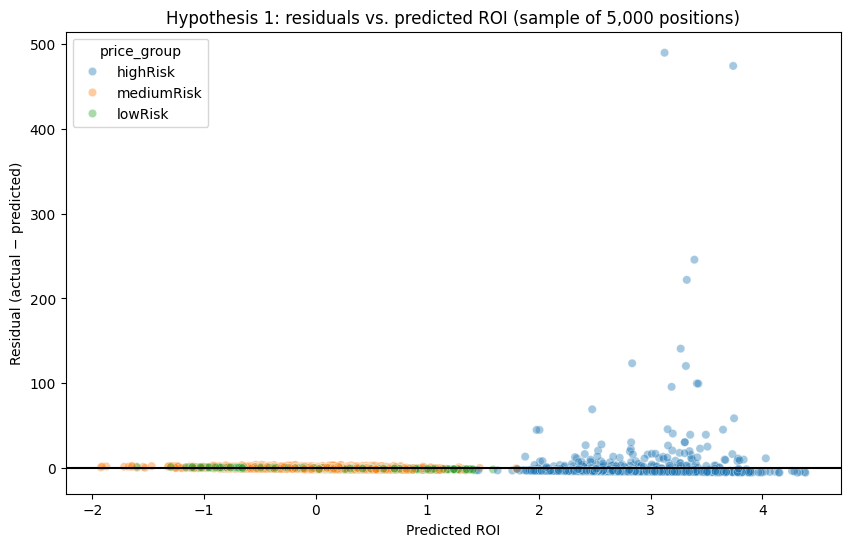

,title,category,avg_price,roi,predicted,residual
226301,Will Rachel Anderson be the Democratic nominee...,politics,0.001,998.962973,2.808321,996.154651
441312,Jamal Murray: Rebounds O/U 4.5,sports,0.001,999.000000,3.092079,995.907921
60300,"Solana Up or Down - September 16, 6AM ET",crypto,0.001,998.931000,3.270287,995.660713
520024,Will S&P 500 (SPY) hit (LOW) $730 Week of June...,econ,0.001,999.000000,3.505431,995.494569
471898,Will S&P 500 (SPY) hit (LOW) $730 Week of June...,econ,0.001,999.000000,3.522603,995.477397


In [ ]:
# Residuals (actual ROI minus predicted ROI), plotted for a random sample of 5,000 positions so the plot is readable
h1_df['predicted'] = h1_model.predict(h1_df[h1_inputs])
h1_df['residual'] = h1_df['roi'] - h1_df['predicted']
sns.scatterplot(data=h1_df.sample(5000, random_state=2950), x='predicted', y='residual',
                hue='price_group', alpha=0.4)
plt.axhline(0, color='black')
plt.title('Hypothesis 1: residuals vs. predicted ROI (sample of 5,000 positions)')
plt.xlabel('Predicted ROI')
plt.ylabel('Residual (actual − predicted)')
plt.show()

# The 5 positions the model misses by the most
h1_df.sort_values('residual', ascending=False)[['title', 'category', 'avg_price', 'roi', 'predicted', 'residual']].head()

**Outliers and oddities.**
- **Most highRisk positions lost everything.** The dense blue band just below the black line is positions with ROI = −1. The model overpredicts almost all of them.
- **A few enormous wins.** A handful of highRisk positions have residuals in the hundreds. All five biggest misses in the table were bought at \$0.001 and returned about 999 times the money spent. These rare "lottery ticket" wins are why $\beta_{highRisk}$ is positive.
- **Impossible predictions.** Some predictions are below −1, but a position can't lose more than it cost. The model shouldn't be trusted far from typical positions.

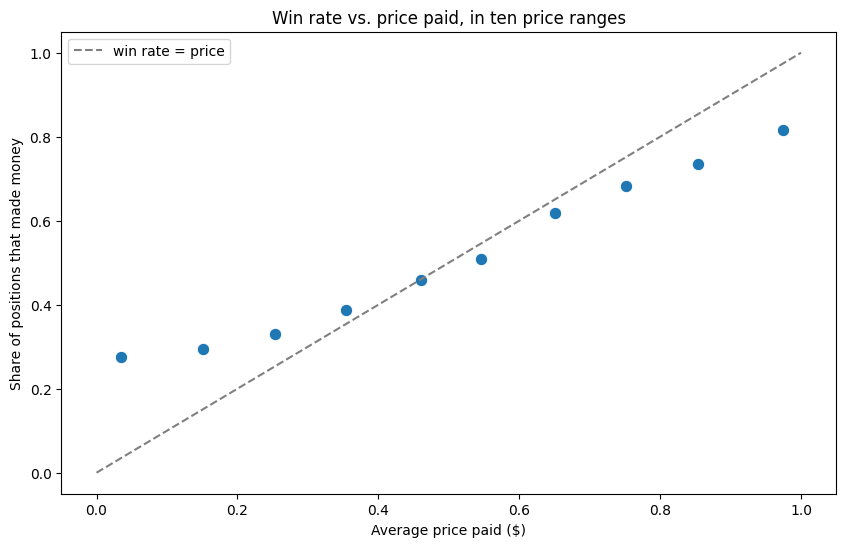

In [ ]:
# Win rate in ten price ranges ($0.00-0.10, $0.10-0.20, ...) vs. the average price in that range
h1_df['price_range'] = pd.cut(h1_df['avg_price'], bins=np.arange(0, 1.01, 0.1))
calibration = h1_df.groupby('price_range', observed=True)[['avg_price', 'won']].mean().reset_index()

sns.scatterplot(data=calibration, x='avg_price', y='won', s=80)
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', label='win rate = price')
plt.title('Win rate vs. price paid, in ten price ranges')
plt.xlabel('Average price paid ($)')
plt.ylabel('Share of positions that made money')
plt.legend()
plt.show()

If prices were accurate probabilities, the points would sit on the dashed line. Instead, cheap positions are **above** it and expensive ones are **below** it. Positions bought for about \$0.03 made money about 28% of the time, far more than the 3% their price implies, while positions bought for about \$0.97 made money only about 82% of the time. This is the **opposite** of the favorite–longshot bias.

Caveat: "made money" includes selling early for a profit, which is easy for cheap shares (a rise from \$0.03 to \$0.04 is enough), so this plot likely overstates how often cheap shares win.

## Hypothesis 2: sportsShare and trader ROI
We use one row per trader, take the natural log of total money spent, and leave out the 92 traders with no tenure.

In [ ]:
# Hypothesis 2 data: one row per trader, leaving out traders with no join date (no tenure)
h2_df = traders_clean_df.dropna(subset=['tenure_months']).copy()
h2_df['log_total_spent'] = np.log(h2_df['total_spent'])
h2_inputs = ['sports_share', 'top_trader', 'highRisk_share', 'log_total_spent', 'positions_per_month', 'tenure_months']
print('traders in the model:', len(h2_df), 'of', len(traders_clean_df))

traders in the model: 1752 of 1844


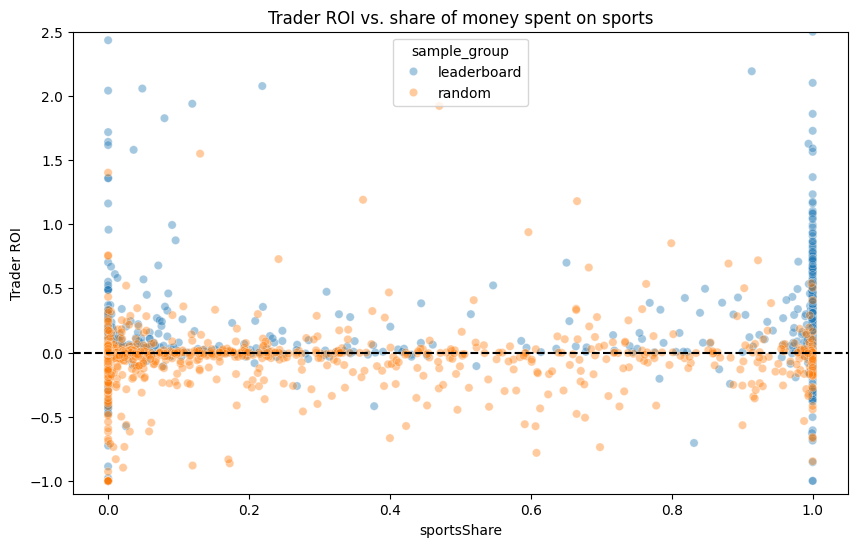

In [ ]:
# Trader ROI vs. sportsShare, by group (y-axis cut at 2.5, which hides about the top 1% of traders)
sns.scatterplot(data=h2_df, x='sports_share', y='trader_roi', hue='sample_group', alpha=0.4)
plt.axhline(0, color='black', linestyle='--')
plt.ylim(-1.1, 2.5)
plt.title('Trader ROI vs. share of money spent on sports')
plt.xlabel('sportsShare')
plt.ylabel('Trader ROI')
plt.show()

**Observations:** Our model shows most traders as sitting at either end of the extremes, where sportsShare is 0 or 1, meaning a lot of traders either invest all their money into sports or do not invest in sports at all.
There appear to be more leaderboard traders who invest all their money into sports than random traders. It also seems that out of the leaderboard traders, more of the ones who invest all their money into sports have high ROI. However, leaderboard traders who don't invest in sports at all also tend to have positive ROI, but not as large as those on the other end.
A slight majority of the random traders appear to have negative ROI, with more random traders who don't invest any money into sports having lower ROI. While random traders who invest all their money into sports also tend to have negative ROI, the numbers are generally not as extreme as those who don't invest in sports.

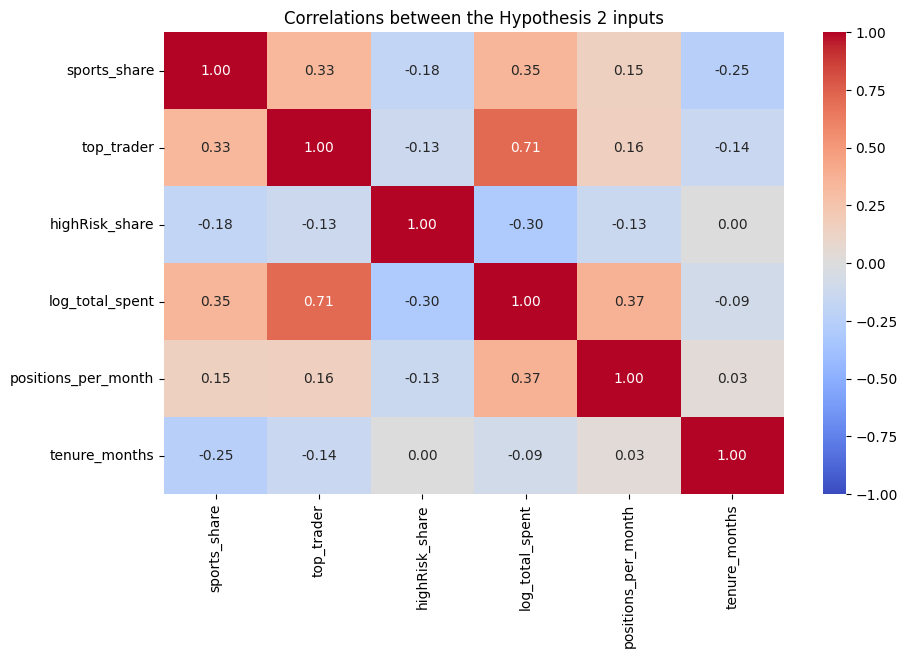

In [ ]:
# Correlations between the Hypothesis 2 inputs
sns.heatmap(h2_df[h2_inputs].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlations between the Hypothesis 2 inputs')
plt.show()

**Observations:** The strongest correlation is between log(total spent) and top_trader (about 0.72; in our Phase 2 EDA we wrongly said none was above 0.5). Leaderboard wallets spend far more money, so these two inputs partly measure the same thing, and their own coefficients may be unstable. Both are controls, so this matters less for our test, as long as sportsShare is not strongly correlated with them.

In [ ]:
# Hypothesis 2 regression
h2_model = LinearRegression()
h2_model.fit(h2_df[h2_inputs], h2_df['trader_roi'])

print('intercept:', round(h2_model.intercept_, 3))
print('R squared:', round(h2_model.score(h2_df[h2_inputs], h2_df['trader_roi']), 4))
pd.DataFrame({'input': h2_inputs, 'coefficient': h2_model.coef_}).round(3)

intercept: -0.139
R squared: 0.1633


,input,coefficient
0,sports_share,0.047
1,top_trader,0.247
2,highRisk_share,0.794
3,log_total_spent,0.020
4,positions_per_month,-0.005
5,tenure_months,-0.005


**Summarizing:** Holding the other inputs fixed, it seems that a trader who puts all of their money on sports has an ROI that's 0.047 higher than a trader who puts none on sports. Leaderboard traders have an ROI that's 0.247 higher than random traders, which we expected, since the leaderboard is chosen by profit. A trader who puts all of their money on high-risk shares (under \$0.20) has an ROI about 0.794 higher than a trader who puts none there, which aligns with our Hypothesis 1 result. Traders who open more positions per month and who have been on Polymarket longer have a slightly lower ROI (each about 0.005 lower per extra position per month or month of tenure). The R² is 0.163, so these inputs explain about 16% of the variation in trader ROI.

In [ ]:
# Predicted ROI for a typical random trader (median of each input among random traders), with sportsShare 0, 0.5, and 1
random_medians = h2_df[h2_df['top_trader'] == 0][h2_inputs].median()
typical_traders = pd.DataFrame([random_medians, random_medians, random_medians], index=['0% sports', '50% sports', '100% sports'])
typical_traders['sports_share'] = [0, 0.5, 1]
typical_traders['predicted_roi'] = h2_model.predict(typical_traders[h2_inputs])
typical_traders[['sports_share', 'predicted_roi']].round(3)

,sports_share,predicted_roi
0% sports,0.0,-0.091
50% sports,0.5,-0.067
100% sports,1.0,-0.044


**Predicting:** For a typical random trader, the model predicts an ROI of −0.091 with no money on sports, −0.067 with half of it on sports, and −0.044 with all of it on sports. So the typical random trader is predicted to lose money no matter how much they put on sports. The all-sports trader is predicted to lose slightly less, the opposite of Hypothesis 2, but the difference is small (about 0.05 between 0% and 100% sports).

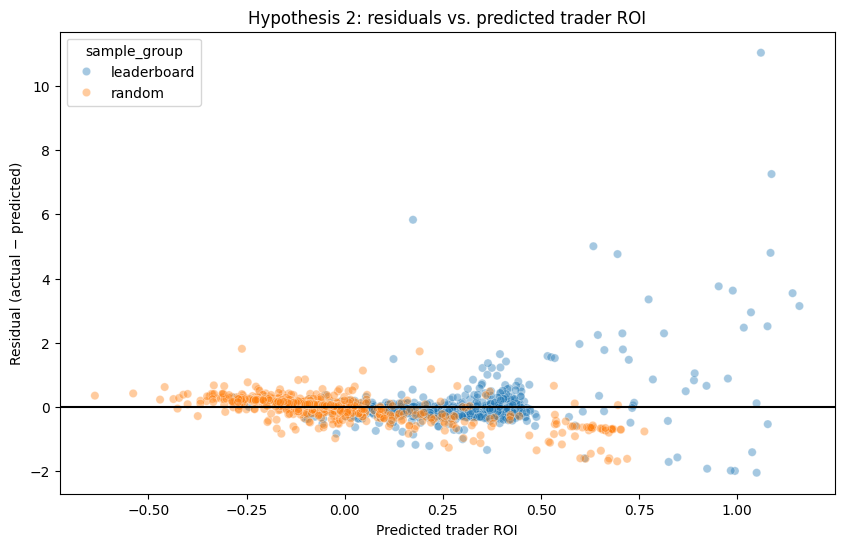

,sample_group,n_positions,total_spent,sports_share,trader_roi,predicted
436,leaderboard,4,33888.843427,0.000000,12.094896,1.060161
742,leaderboard,2,30541.986039,0.999262,8.342461,1.087228
805,leaderboard,980,33381.662970,0.032168,6.004557,0.173925
312,leaderboard,21,96300.121005,0.000000,5.639539,0.633459
434,leaderboard,3,69739.234840,0.000000,5.884808,1.084711


In [ ]:
# Residuals for every trader
h2_df['predicted'] = h2_model.predict(h2_df[h2_inputs])
h2_df['residual'] = h2_df['trader_roi'] - h2_df['predicted']
sns.scatterplot(data=h2_df, x='predicted', y='residual', hue='sample_group', alpha=0.4)
plt.axhline(0, color='black')
plt.title('Hypothesis 2: residuals vs. predicted trader ROI')
plt.xlabel('Predicted trader ROI')
plt.ylabel('Residual (actual − predicted)')
plt.show()

# The 5 traders the model misses by the most (in either direction)
h2_df['abs_residual'] = h2_df['residual'].abs()
h2_df.sort_values('abs_residual', ascending=False)[['sample_group', 'n_positions', 'total_spent', 'sports_share', 'trader_roi', 'predicted']].head()

**Inspect oddities/outliers:** Most traders, especially random ones, sit close to the zero line, so the model's errors for them are small. The errors grow as the predicted ROI gets larger. For traders with a predicted ROI above about 0.5, mostly leaderboard traders, the actual ROI can be several points above or below the prediction. All five traders the model misses by the most are leaderboard traders who earned far more than predicted, with actual ROIs between 5.6 and 12.1. Three of them have only 2 to 4 positions, so their ROI comes from just a few bets and is mostly luck. One has 21 positions, and only one (980 positions) is a very active trader. There is also a group of random traders with a predicted ROI of about 0.6 to 0.75 whose actual ROI was well below that, so the model is too optimistic for some random traders. Overall, the model fits ordinary traders much better than the few traders with extreme returns.

# __EVALUATION OF SIGNIFICANCE__
We test each hypothesis with a t-test on its regression coefficient. We refit the same two models with statsmodels, which gives each coefficient's standard error (SE), t-statistic ($t = b / SE_b$), and p-value.

- **Null hypothesis:** $\beta = 0$ (no relationship).
- **Alternative hypothesis:** $\beta < 0$. Both of our hypotheses predict a *negative* coefficient, so our tests are one-tailed.

The regression table's `P>|t|` column is a two-tailed p-value. For a one-tailed test, when the coefficient is negative (the direction we predicted), the one-tailed p-value is half of it. We reject the null hypothesis if the one-tailed p-value is below 0.05.

### Hypothesis 1

In [ ]:
# Hypothesis 1: the same regression as above, fit with statsmodels to get standard errors and p-values
X1 = sm.add_constant(h1_df[h1_inputs])
h1_results = sm.OLS(h1_df['roi'], X1).fit()
print(h1_results.summary())

                            OLS Regression Results                            
Dep. Variable:                    roi   R-squared:                       0.011
Model:                            OLS   Adj. R-squared:                  0.011
Method:                 Least Squares   F-statistic:                     519.2
Date:                Mon, 02 Nov 2026   Prob (F-statistic):               0.00
Time:                        00:33:48   Log-Likelihood:            -2.1579e+06
No. Observations:              552451   AIC:                         4.316e+06
Df Residuals:                  552438   BIC:                         4.316e+06
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const               -1.3998      0.089  

In [ ]:
# One-tailed t-test for beta_highRisk (null: beta = 0, alternative: beta < 0)
b1 = h1_results.params['highRisk']
se1 = h1_results.bse['highRisk']
t1 = h1_results.tvalues['highRisk']
p1_two = h1_results.pvalues['highRisk']
if b1 < 0:
    p1_one = p1_two / 2
else:
    p1_one = 1 - p1_two / 2
print(f'beta_highRisk = {b1:.3f}, SE = {se1:.3f}, t = {t1:.2f}, one-tailed p-value = {p1_one:.4f}')

beta_highRisk = 2.504, SE = 0.046, t = 54.68, one-tailed p-value = 1.0000


**Hypothesis 1 result.** $\beta_{highRisk}$ = 2.504 (SE = 0.046, t = 54.68), and the one-tailed p-value is 1.0000. The 95% confidence interval in the regression table is [2.414, 2.594]. Because the coefficient is positive, we fail to reject the null hypothesis. In fact, holding money spent, holding time, event volume, and category fixed, highRisk positions had a *higher* average ROI than mediumRisk positions, by about 2.5 (250 percentage points), the opposite of what we expected. This average is probably driven by a small number of very large wins on cheap shares (ROI can reach 999). The regression table also shows that ROI is extremely skewed (skew = 37.9), so the t-test's assumption of normally distributed errors does not hold well here.

This matters because, in our sample, cheap shares were not the money-losers that the favorite–longshot bias predicts: on average, a few huge payoffs more than made up for the many total losses. Our sample over-represents successful traders (see Limitations), so this may not hold for all Polymarket users.

### Hypothesis 2

In [ ]:
# Hypothesis 2: the same regression as above, fit with statsmodels to get standard errors and p-values
X2 = sm.add_constant(h2_df[h2_inputs])
h2_results = sm.OLS(h2_df['trader_roi'], X2).fit()
print(h2_results.summary())

                            OLS Regression Results                            
Dep. Variable:             trader_roi   R-squared:                       0.163
Model:                            OLS   Adj. R-squared:                  0.160
Method:                 Least Squares   F-statistic:                     56.77
Date:                Mon, 02 Nov 2026   Prob (F-statistic):           2.83e-64
Time:                        00:33:48   Log-Likelihood:                -1537.3
No. Observations:                1752   AIC:                             3089.
Df Residuals:                    1745   BIC:                             3127.
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                  -0.1389    

In [ ]:
# One-tailed t-test for beta_sportsShare (null: beta = 0, alternative: beta < 0)
b2 = h2_results.params['sports_share']
se2 = h2_results.bse['sports_share']
t2 = h2_results.tvalues['sports_share']
p2_two = h2_results.pvalues['sports_share']
if b2 < 0:
    p2_one = p2_two / 2
else:
    p2_one = 1 - p2_two / 2
print(f'beta_sportsShare = {b2:.3f}, SE = {se2:.3f}, t = {t2:.2f}, one-tailed p-value = {p2_one:.4f}')

beta_sportsShare = 0.047, SE = 0.036, t = 1.32, one-tailed p-value = 0.9057


**Hypothesis 2 result.** $\beta_{sportsShare}$ = 0.047 (SE = 0.036, t = 1.32), and the one-tailed p-value is 0.906. The 95% confidence interval in the regression table is [−0.023, 0.117]. We fail to reject the null hypothesis: our data doesn't show that traders who bet more on sports earn less. The coefficient is slightly positive and the interval includes 0, so once the other inputs are held fixed, sportsShare isn't clearly related to trader ROI in either direction.

This matters because sports had the lowest average position ROI in our EDA, but that doesn't carry over to traders: the share of money a trader puts on sports doesn't explain their overall return. Other inputs do: top_trader, highRiskShare, and positions per month all have p-values below 0.05. Traders who put more of their money on cheap shares had a higher ROI (coefficient 0.79), which matches our Hypothesis 1 result.

# __CONCLUSIONS__
**Position level.** Cheap (highRisk) positions did not have a lower ROI than mediumRisk positions. Holding money spent, holding time, event volume, and category fixed, their average ROI was about 2.5 higher (95% CI [2.414, 2.594]), so we fail to reject the null hypothesis for Hypothesis 1. This average is driven by a few enormous wins on shares bought for \$0.001, while most highRisk positions lost everything, so a typical cheap bet still loses money. Our win-rate plot points the same way: cheap positions made money more often than their prices implied, although this partly reflects selling early for a small profit. Among the other inputs, crypto positions had the highest ROI (0.73 higher than sports), and larger positions had a slightly lower ROI.

**Trader level.** The share of money a trader puts on sports was not clearly related to their ROI (coefficient 0.047, 95% CI [−0.023, 0.117]), so we fail to reject the null hypothesis for Hypothesis 2. Other behaviors mattered more: leaderboard traders had an ROI 0.247 higher than random traders, traders who put more of their money on cheap shares had a higher ROI (coefficient 0.794), and traders who opened more positions per month had a slightly lower ROI.

**Main question.** In our sample, the positions and traders that did better were the ones that took on more risk by buying cheap shares, not the ones that avoided sports. However, these results rest on a small number of very large wins, our sample over-represents successful traders, and our p-values are probably too small because positions by the same trader are not independent. We see these results as patterns worth checking further, not firm rules.

These are associations, not causes: for example, the fact that traders who put more money on cheap shares earned more doesn't mean that buying more cheap shares would raise anyone's returns.

# __LIMITATIONS__
- **The random group isn't completely random.** Traders who trade often, and who trade near the end of a market, are more likely to be picked. So the non-leaderboard group is probably more skilled than the average user. *Effect:* our results describe active traders, not all Polymarket users, and the true gap between top and ordinary traders is probably larger than what we find.
- **Survivorship bias.** Traders who quit before October 2025 are not in our random group. *Effect:* both groups look more successful than Polymarket users overall, so our ROI averages are probably too high.
- **One person can have several wallets.** We treat each wallet as a trader. *Effect:* someone who splits their trading across wallets looks more focused (higher sportsShare or CategoryHHI) than they really are, which blurs the relationship we test in Hypothesis 2.
- **Many top wallets are probably bots**, given how many trades they make per day. *Effect:* `top_trader` may partly measure automated strategies rather than human skill, so we don't read its coefficient as "skill".
- **Positions are not independent.** Positions by the same trader share that trader's skill, and positions in the same market share the same outcome. *Effect:* the standard errors from statsmodels assume every row is independent. Since they aren't, our standard errors are probably too small and our p-values too low, especially for Hypothesis 1, where some traders have up to 1,500 positions.
- **Missing data is not evenly spread.** Event volume is missing for 4.6% of positions, mostly crypto (14.4% of crypto positions, under 3% for every other category), and more for leaderboard positions (5.8%) than random ones (3.2%). Tenure is missing for 92 of 1,844 traders (5.0%), mostly random traders (7.6% vs. 2.1%). In our Phase 2 EDA, "unknown" showed 100% missing volume, but that was only the 40 positions (0.007%) that had no event information at all. *Effect:* the main models slightly under-represent crypto and leaderboard positions (Hypothesis 1) and random traders (Hypothesis 2). We can't tell whether including these positions and traders would change our results.
- **We could not include Combos.** Combos (parlay-style bets on several events) only launched around June 10, 2026, and only for sports. *Effect:* if combo bets have different returns, part of what we attribute to sportsShare may come from combos.
- **Limits of our significance tests.** The t-test assumes the errors are normally distributed around 0, but position ROI is mostly −1 or a large win, so this assumption doesn't hold well. A p-value below 0.05 also still allows a 5% chance of rejecting a null hypothesis that is true. With over 500,000 positions, even a tiny effect can be "significant", so we also report how large each effect is. Finally, our models have a low R², so they describe average differences, not what will happen to any one bet.

__Potential harms__
- Although we stress that we're not trying to give advice, it's possible that results from our project could read like suggestions. Our work might still encourage gambling, especially since our data over-represents successful traders and trades, as mentioned in the first two limitations.
- There are ethical concerns with analyzing markets pertaining to predicting wars, disasters, deaths, and controversial topics. We do not analyze them separately, but they're included in our category averages.
- Our data describes real people's gains and losses. Even with wallet addresses replaced by numbers, someone could match a large position back to its public wallet on the blockchain, so we don't publish individual traders' results.

# __ACKNOWLEDGEMENTS AND BIBLIOGRAPHY__
**Acknowledgements.** Our data comes from Polymarket's public Data API and Gamma API, which Polymarket provides for free. Trades are recorded on the Polygon blockchain, and markets are resolved through UMA. We used Python with pandas, NumPy, DuckDB, requests, seaborn, Matplotlib, scikit-learn, and statsmodels.

**Literature**
- Apesteguia, J., Oechssler, J., & Weidenholzer, S. (2020). Copy trading. *Management Science, 66*(12), 5608–5622.
- Barber, B. M., Lee, Y.-T., Liu, Y.-J., & Odean, T. (2014). The cross-section of speculator skill: Evidence from day trading. *Journal of Financial Markets, 18*, 1–24.
- Barber, B. M., & Odean, T. (2000). Trading is hazardous to your wealth: The common stock investment performance of individual investors. *The Journal of Finance, 55*(2), 773–806.
- Britannica Money. (n.d.). *Polymarket*. Encyclopaedia Britannica. https://www.britannica.com/money/Polymarket
- Brown, S. J., Goetzmann, W. N., Ibbotson, R. G., & Ross, S. A. (1992). Survivorship bias in performance studies. *The Review of Financial Studies, 5*(4), 553–580.
- Gebru, T., Morgenstern, J., Vecchione, B., Vaughan, J. W., Wallach, H., Daumé III, H., & Crawford, K. (2021). Datasheets for datasets. *Communications of the ACM, 64*(12), 86–92.
- Levitt, S. D. (2004). Why are gambling markets organised so differently from financial markets? *The Economic Journal, 114*(495), 223–246.
- Page, L., & Clemen, R. T. (2013). Do prediction markets produce well-calibrated probability forecasts? *The Economic Journal, 123*(568), 491–513.
- Rothschild, D. M., & Sethi, R. (2016). Trading strategies and market microstructure: Evidence from a prediction market. *The Journal of Prediction Markets, 10*(1), 1–29.
- Snowberg, E., & Wolfers, J. (2010). Explaining the favorite–long shot bias: Is it risk-love or misperceptions? *Journal of Political Economy, 118*(4), 723–746.
- Thaler, R. H., & Ziemba, W. T. (1988). Anomalies: Parimutuel betting markets: Racetracks and lotteries. *Journal of Economic Perspectives, 2*(2), 161–174.
- Wolfers, J., & Zitzewitz, E. (2004). Prediction markets. *Journal of Economic Perspectives, 18*(2), 107–126.

**Data documentation**
- Polymarket. (n.d.). *Data API overview*. Retrieved October 11, 2026, from https://docs.polymarket.com/api-reference/data-api/overview
- Polymarket. (n.d.). *Data API v2 reference*. Retrieved October 11, 2026, from https://data-api.polymarket.com/v2/docs
- Polymarket. (n.d.). *List events*. Retrieved October 11, 2026, from https://docs.polymarket.com/api-reference/events/list-events.md

**Code documentation**
- DuckDB. (n.d.). *CASE expression*. https://duckdb.org/docs/current/sql/expressions/case
- Investopedia. (n.d.). *Herfindahl-Hirschman Index (HHI)*. https://www.investopedia.com/terms/h/hhi.asp
- Matplotlib. (n.d.). *matplotlib.axes.Axes.axhline*. https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.axhline.html
- pandas. (n.d.). *pandas.Series.clip*. https://pandas.pydata.org/docs/reference/api/pandas.Series.clip.html
- pandas. (n.d.). *pandas.Series.quantile*. https://pandas.pydata.org/docs/reference/api/pandas.Series.quantile.html
- pandas. (n.d.). *pandas.cut*. https://pandas.pydata.org/docs/reference/api/pandas.cut.html
- requests. (n.d.). *Requests: HTTP for Humans*. https://requests.readthedocs.io/en/latest/
- seaborn. (n.d.). *seaborn.heatmap*. https://seaborn.pydata.org/generated/seaborn.heatmap.html
- seaborn. (n.d.). *seaborn.histplot*. https://seaborn.pydata.org/generated/seaborn.histplot.html
- statsmodels. (n.d.). *Linear regression*. https://www.statsmodels.org/stable/regression.html

# __QUESTIONS FOR REVIEWERS__
- Our models have a low R². Is that a problem for answering our questions, given that a single bet's outcome is mostly luck?
- Our Hypothesis 1 p-value assumes every position is independent, but positions by the same trader are related. How much of a problem is that, and is there a simple way to account for it?
- Is the win-rate vs. price plot convincing evidence on its own, or should we drop it?
- log(total spent) and top trader are correlated at 0.72. Should we drop one of them from the Hypothesis 2 model?
- Is the story from our two hypotheses to our conclusion easy to follow?